# 4. Transit light curves

`obs.light_curves()` turns a simulated spectrum into the time domain: one
white-light curve, or several split by wavelength band so you can watch the
transit depth change with colour.

The shape is a quadratically limb-darkened transit computed by numpy-only
numerical disk integration. The geometry comes from the frozen NASA Exoplanet
Archive registry, with z(t) the exact sky-projected separation of the Keplerian
orbit, and the limb-darkening coefficients from per-planet exotic-ld tables.
Planets with no registry entry or no LD table fall back to a b = 0 trapezoid, and
`meta["shape"]` records which model was used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__version__ if hasattr(lazuli_exo, "__version__") else "(dev)")

lazuli_exo (dev)


## The white-light curve

With `n_groups=1` every spectral bin is combined into a single light curve. The
observation window is ±t<sub>14</sub> around mid-transit (the equal
out-of-transit baseline the noise tables assume), sampled at the instrument's
native integration time. `lc.plot()` draws the noisy realization over the model.

In [2]:
PLANET = "WASP-39 b"

obs = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=100)
lc = obs.light_curves(n_groups=1, seed=0)

print(f"labels:      {lc.labels}")
print(f"time_hr:     {lc.time_hr.size} samples, "
      f"{lc.time_hr[0]:+.2f} to {lc.time_hr[-1]:+.2f} h")
print(f"cadence:     {lc.cadence_s:.2f} s")
print(f"t14:         {lc.t14_s:.1f} s  ({lc.t14_s / 3600:.2f} h)")
print(f"depth:       {lc.depth[0] * 100:.4f} %")
print(f"sigma/point: {lc.sigma_point[0] * 1e6:.1f} ppm")
print(f"\nmeta: {lc.meta}")

labels:      ['white light']
time_hr:     419 samples, -2.79 to +2.79 h
cadence:     48.11 s
t14:         10091.5 s  (2.80 h)
depth:       2.1316 %
sigma/point: 90.9 ppm

meta: {'planet': 'WASP-39 b', 'scenario': 'clear', 'n_transits': 1, 'shape': 'quadratic-ld', 'b': 0.532570994641176, 'a_over_rs': 11.39, 't14_geom_s': 9960.196814117857, 'time_stretch': 0.9869867784157249}


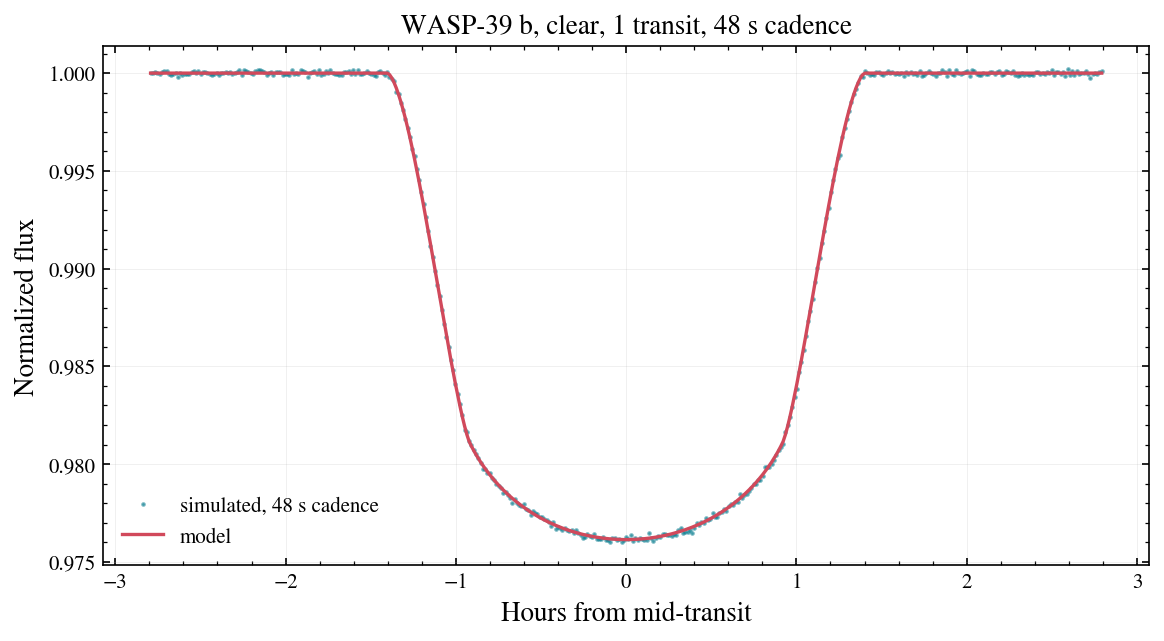

In [3]:
lc.plot()
plt.show()

## Wavelength-banded light curves

`n_groups > 1` splits the spectrum into contiguous bands of equal bin count. The
geometry is shared, and each band gets its own depth and its own limb darkening,
so the curves are not scaled copies of one another. `lcb.plot()` stacks them with
an offset; pass `offset=` to change the spacing.

In [4]:
lcb = obs.light_curves(n_groups=5, seed=0)

print(f"{'band':18s}{'depth (%)':>11s}{'u1':>8s}{'u2':>8s}"
      f"{'sigma/pt (ppm)':>16s}")
for i, lab in enumerate(lcb.labels):
    print(f"{lab:18s}{lcb.depth[i] * 100:11.4f}"
          f"{lcb.u1[i]:8.3f}{lcb.u2[i]:8.3f}"
          f"{lcb.sigma_point[i] * 1e6:16.1f}")

band                depth (%)      u1      u2  sigma/pt (ppm)
0.40-0.53 um           2.1176   0.782   0.056           365.7
0.54-0.71 um           2.1639   0.536   0.162           246.8
0.72-0.95 um           2.1162   0.385   0.179           199.0
0.96-1.26 um           2.0950   0.292   0.195           164.4
1.28-1.68 um           2.1696   0.176   0.272           169.6


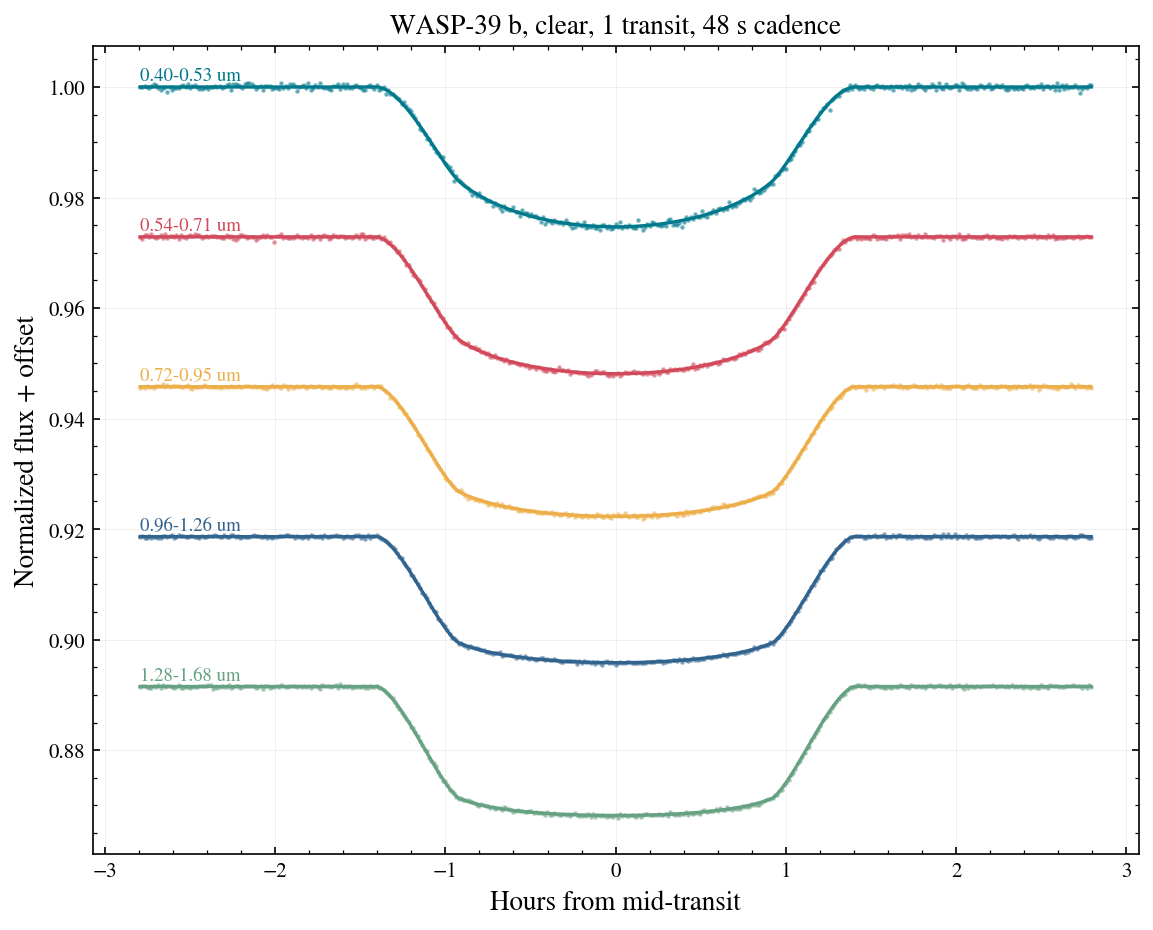

In [5]:
lcb.plot()
plt.show()

## Validating `transit_flux`

The occultation model is `lazuli_exo.lightcurve.transit_flux(z, k, u1, u2)`:
normalized flux for an opaque disk of radius ratio `k` at projected separations
`z` in stellar radii. With `u1 = u2 = 0` it must reduce to the analytic
uniform-disk overlap, a closed-form expression, so the check is worth running
rather than assuming.

In [6]:
from lazuli_exo.lightcurve import transit_flux


def uniform_disk_flux(z, k):
    """Analytic uniform-source occultation (Mandel & Agol 2002, lambda_e)."""
    z = np.abs(np.asarray(z, float))
    out = np.ones_like(z)

    full = z <= 1.0 - k                      # planet fully on the disk
    out[full] = 1.0 - k ** 2

    part = (np.abs(1.0 - k) < z) & (z <= 1.0 + k)   # partial overlap
    zp = z[part]
    k0 = np.arccos((k ** 2 + zp ** 2 - 1.0) / (2.0 * k * zp))
    k1 = np.arccos((1.0 - k ** 2 + zp ** 2) / (2.0 * zp))
    area = (k ** 2 * k0 + k1
            - np.sqrt(4.0 * zp ** 2 - (1.0 + zp ** 2 - k ** 2) ** 2) / 2.0)
    out[part] = 1.0 - area / np.pi
    return out


z = np.linspace(0.0, 1.4, 601)
k = 0.15

numeric = transit_flux(z, k, 0.0, 0.0)
analytic = uniform_disk_flux(z, k)
err = np.abs(numeric - analytic)

print(f"k = {k}, {z.size} separations")
print(f"max |numeric - analytic|: {err.max():.3e}")
print(f"in ppm of the depth:      {err.max() / k ** 2 * 1e6:.2f} ppm")

assert err.max() < 1e-5, "uniform-disk limit must be recovered"
print("\nOK: the uniform-disk limit is recovered.")

k = 0.15, 601 separations
max |numeric - analytic|: 3.005e-07
in ppm of the depth:      13.35 ppm

OK: the uniform-disk limit is recovered.


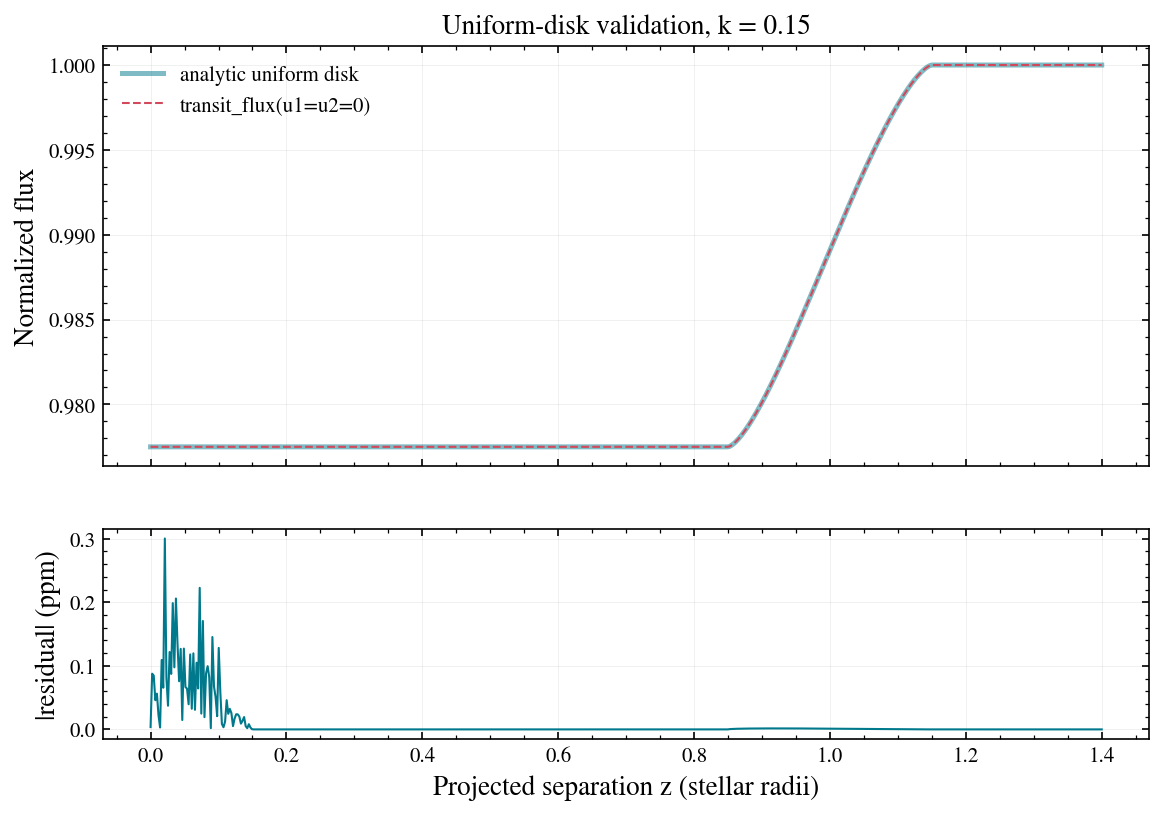

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(z, analytic, lw=2.4, alpha=0.5, label="analytic uniform disk")
ax1.plot(z, numeric, lw=1.0, ls="--", label="transit_flux(u1=u2=0)")
ax1.set_ylabel("Normalized flux")
ax1.legend(frameon=False)
ax1.set_title(f"Uniform-disk validation, k = {k}")

ax2.plot(z, err * 1e6, lw=1.0)
ax2.set_xlabel("Projected separation z (stellar radii)")
ax2.set_ylabel("|residual| (ppm)")
plt.show()

## Limb darkening

The coefficients come from per-planet tables built with exotic-ld on a PHOENIX
grid, refit under the Kipping (2013) constraints so the intensity profile stays
physical. They vary strongly across the band, with much stronger limb darkening
in the blue than in the near-IR, which is why the banded curves above change
shape as well as depth.

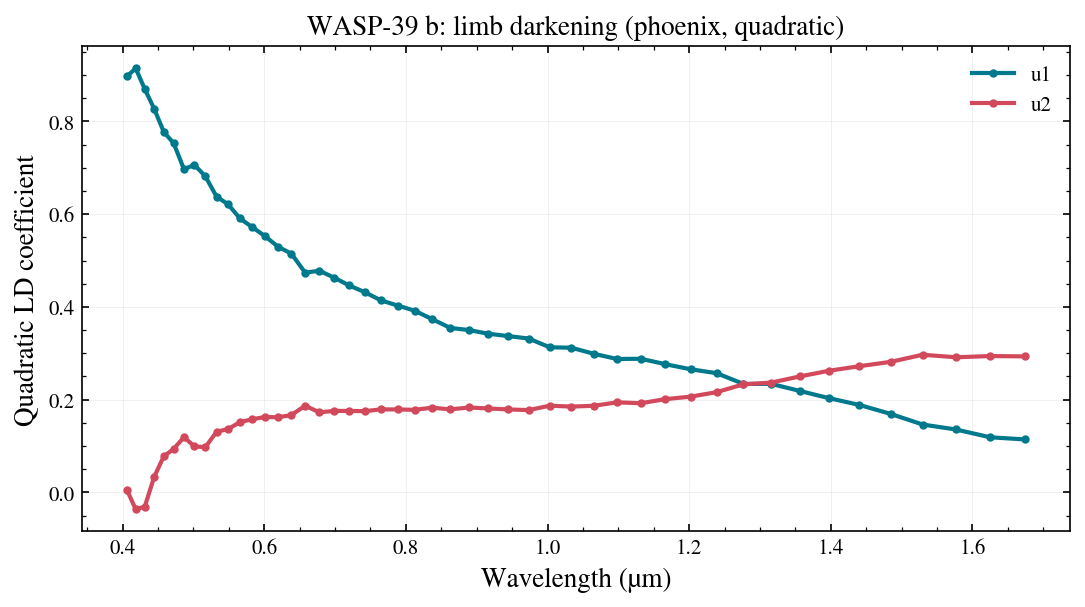

grid point used: Teff=5485.0, logg=4.453, M_H=0.01
inputs clamped to grid: []
48 wavelength chunks over [0.4, 1.7] um


In [8]:
from lazuli_exo import tables

tdir = tables.resolve_tables_dir(None)
wl_ld, u1_ld, u2_ld, ld_meta = tables.load_ld(tdir, PLANET)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(wl_ld, u1_ld, "o-", ms=3, label="u1")
ax.plot(wl_ld, u2_ld, "o-", ms=3, label="u2")
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Quadratic LD coefficient")
ax.set_title(f"{PLANET}: limb darkening ({ld_meta['ld_grid']}, "
             f"{ld_meta['law']})")
ax.legend(frameon=False)
plt.show()

print(f"grid point used: Teff={ld_meta['Teff_used']}, "
      f"logg={ld_meta['logg_used']}, M_H={ld_meta['M_H_used']}")
print(f"inputs clamped to grid: {ld_meta['inputs_clamped']}")
print(f"{wl_ld.size} wavelength chunks over "
      f"{ld_meta['wl_range_um']} um")

The effect on the curve shape is easiest to see by holding the depth fixed and
sweeping the coefficients.

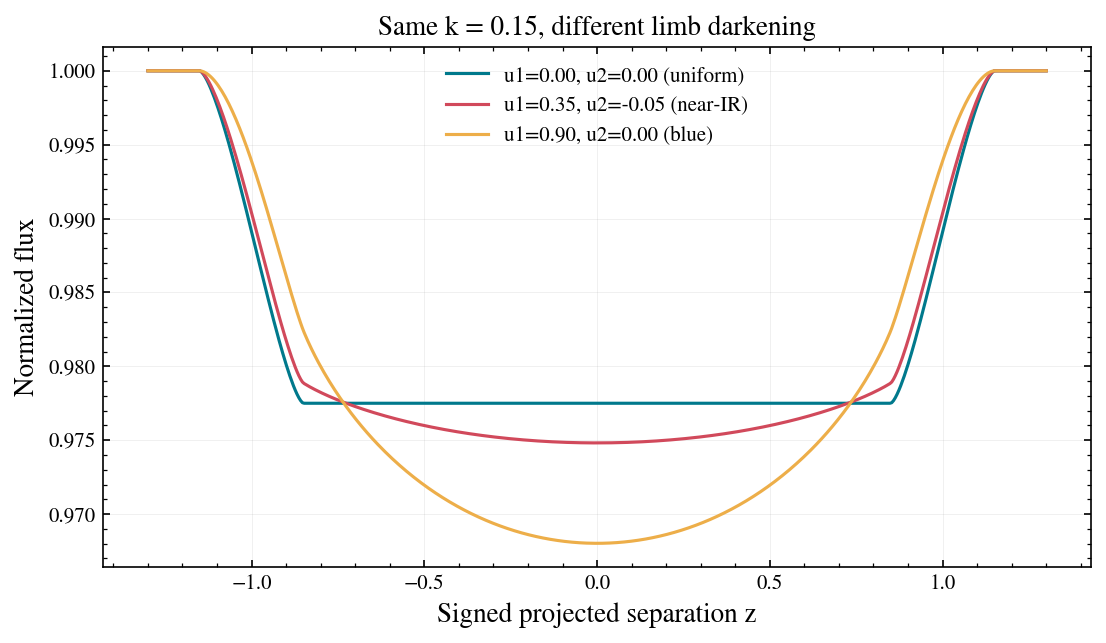

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

zz = np.linspace(-1.3, 1.3, 501)
for u1, u2, lab in [(0.0, 0.0, "u1=0.00, u2=0.00 (uniform)"),
                    (0.35, -0.05, "u1=0.35, u2=-0.05 (near-IR)"),
                    (0.90, 0.00, "u1=0.90, u2=0.00 (blue)")]:
    ax.plot(zz, transit_flux(np.abs(zz), 0.15, u1, u2), lw=1.5, label=lab)

ax.set_xlabel("Signed projected separation z")
ax.set_ylabel("Normalized flux")
ax.set_title("Same k = 0.15, different limb darkening")
ax.legend(frameon=False)
plt.show()

## Geometry from the registry

The impact parameter and the orbit come from the frozen registry: b from
a/R<sub>*</sub> and cos i with an eccentricity factor, and z(t) from Kepler's
equation (`lazuli_exo.orbit.projected_separation`) with mid-transit at inferior
conjunction, so z(0) = b exactly.

The registry t<sub>14</sub> is the measured archive duration and sets the noise
and the window. The geometric duration from (P, a/R<sub>*</sub>, k, i, e, ω) can
differ, so the orbit clock is stretched by their ratio and the model's
first-to-fourth-contact duration equals t<sub>14</sub>. Both numbers are in
`lc.meta`.

In [10]:
from lazuli_exo.targets import get_target

t = get_target(PLANET)
for key in ["period_d", "a_over_rs", "inc_deg", "ecc", "w_deg", "t14_s",
            "depth", "provenance"]:
    print(f"  {key:12s} {t[key]}")

print(f"\nderived by light_curves(): shape={lc.meta['shape']}, "
      f"b={lc.meta['b']:.3f}, a/Rs={lc.meta['a_over_rs']}, "
      f"t14_geom={lc.meta['t14_geom_s']:.0f} s, "
      f"time_stretch={lc.meta['time_stretch']:.4f}")

  period_d     4.0552941
  a_over_rs    11.39
  inc_deg      87.32
  ecc          0.0
  w_deg        90.0
  t14_s        10091.52
  depth        0.02122849
  provenance   NEA PSCompPars

derived by light_curves(): shape=quadratic-ld, b=0.533, a/Rs=11.39, t14_geom=9960 s, time_stretch=0.9870


## The trapezoid fallback

If a planet is not in the registry, or has no LD table, the shape falls back to
a b = 0 trapezoid with no limb darkening. Relabelling an observation is enough
to trigger it, and `meta["shape"]` tells you it happened. `plot(ax=ax,
show_points=False, label=...)` overlays the two models.

In [11]:
import dataclasses

synthetic = dataclasses.replace(obs, planet="Synthetic b")
lc_fallback = synthetic.light_curves(n_groups=1, seed=0)

print(f"registry planet: shape={lc.meta['shape']!r}, "
      f"u1={lc.u1[0]:.3f}")
print(f"synthetic name:  shape={lc_fallback.meta['shape']!r}, "
      f"u1={lc_fallback.u1}")

assert lc.meta["shape"] == "quadratic-ld"
assert lc_fallback.meta["shape"] == "trapezoid"
assert lc_fallback.u1 is None

registry planet: shape='quadratic-ld', u1=0.434
synthetic name:  shape='trapezoid', u1=None


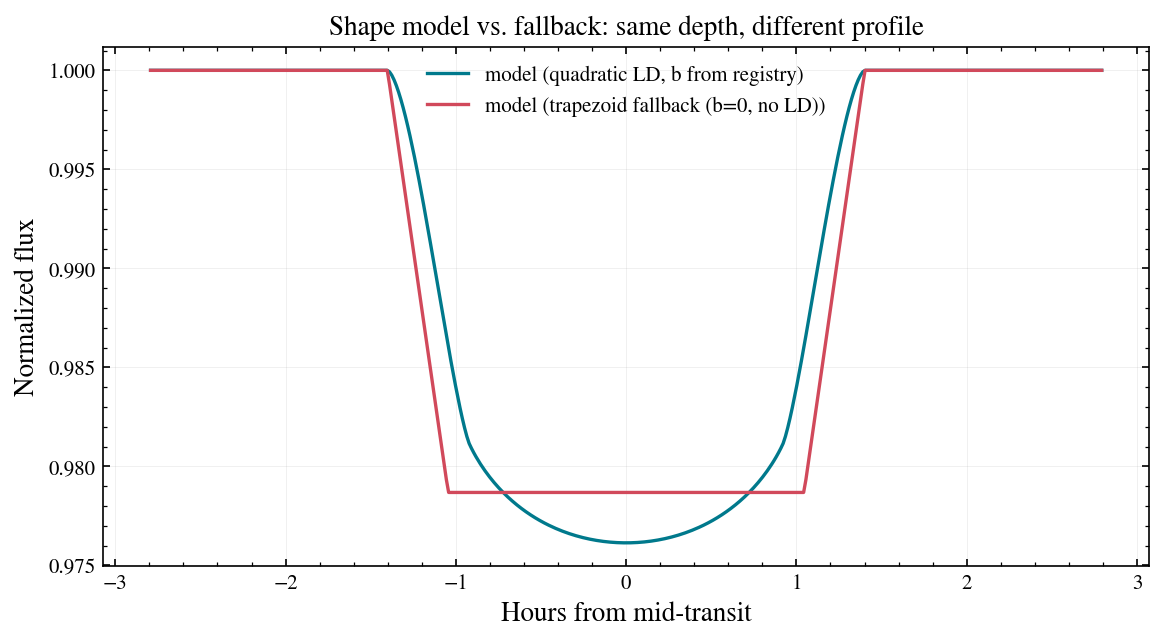

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
lc.plot(ax=ax, show_points=False, label="quadratic LD, b from registry")
lc_fallback.plot(ax=ax, show_points=False, label="trapezoid fallback (b=0, no LD)")
ax.set_title("Shape model vs. fallback: same depth, different profile")
plt.show()

## Per-point noise

The scatter per sample is derived from the band's depth precision rather than
computed independently: σ<sub>pt</sub> = σ<sub>band</sub>
√(t<sub>14</sub>/2c) for cadence c. This keeps the light curves consistent with
the same equal out-of-transit baseline assumption the spectra use.

In [13]:
# reconstruct the band-combined depth precision from the public arrays:
# contiguous equal-count groups, combined in inverse variance
groups = np.array_split(np.arange(obs.depth.size), 5)
w = 1.0 / obs.depth_err ** 2
sigma_band = np.array([1.0 / np.sqrt(w[g].sum()) for g in groups])

expected = sigma_band * np.sqrt(lcb.t14_s / (2.0 * lcb.cadence_s))

print(f"{'band':18s}{'sigma_band (ppm)':>18s}{'sigma_pt (ppm)':>16s}"
      f"{'expected':>12s}")
for i, lab in enumerate(lcb.labels):
    print(f"{lab:18s}{sigma_band[i] * 1e6:18.1f}"
          f"{lcb.sigma_point[i] * 1e6:16.1f}{expected[i] * 1e6:12.1f}")

assert np.allclose(lcb.sigma_point, expected)
print("\nOK: sigma_pt = sigma_band * sqrt(t14 / 2c).")

band                sigma_band (ppm)  sigma_pt (ppm)    expected
0.40-0.53 um                    35.7           365.7       365.7
0.54-0.71 um                    24.1           246.8       246.8
0.72-0.95 um                    19.4           199.0       199.0
0.96-1.26 um                    16.1           164.4       164.4
1.28-1.68 um                    16.6           169.6       169.6

OK: sigma_pt = sigma_band * sqrt(t14 / 2c).


Co-adding transits sharpens the light curves the same way it sharpens the
spectra: the per-point scatter drops as 1/√N while the model is unchanged.

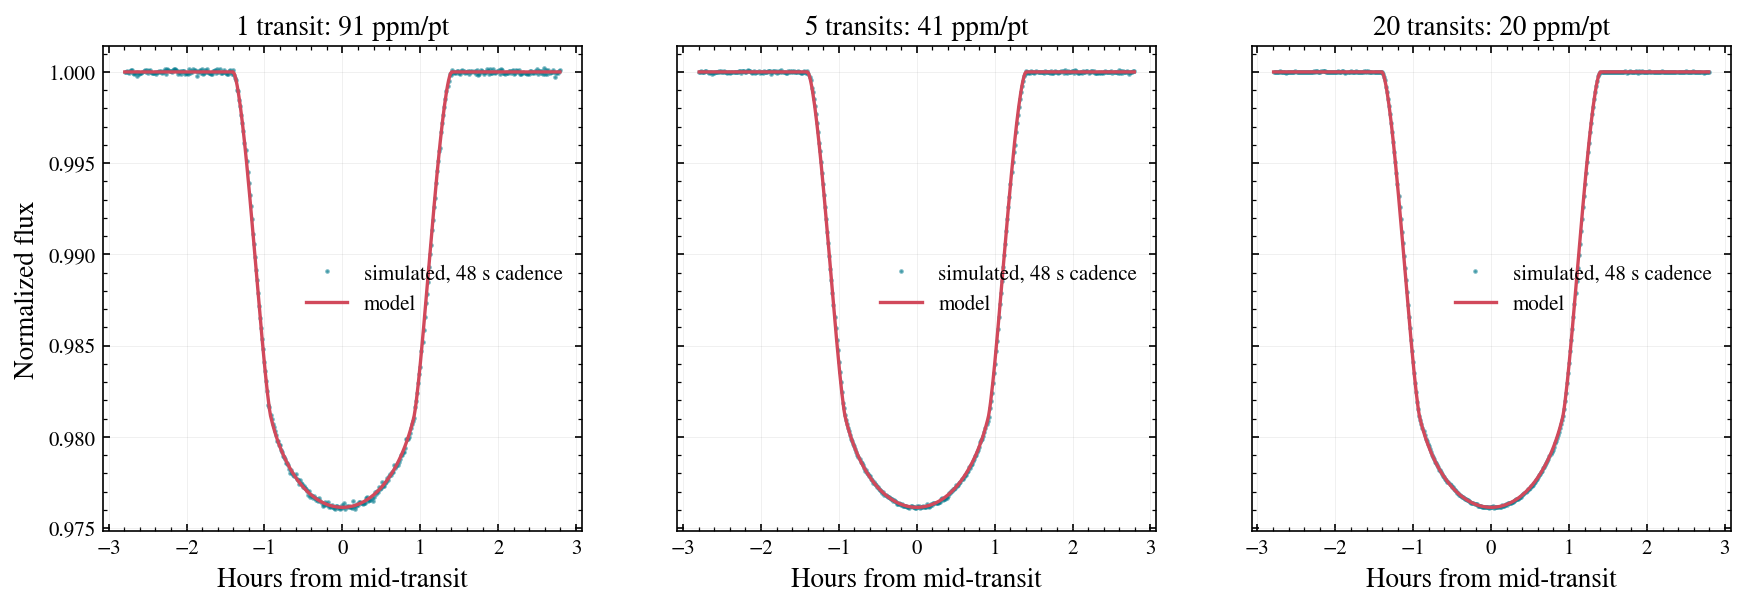

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

for ax, n in zip(axes, [1, 5, 20]):
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=n, R=100)
    curve = o.light_curves(n_groups=1, seed=0)
    curve.plot(ax=ax, title=f"{n} transit{'s' if n > 1 else ''}: "
                            f"{curve.sigma_point[0] * 1e6:.0f} ppm/pt")
for ax in axes[1:]:
    ax.set_ylabel("")
plt.show()

## Summary

- `obs.light_curves(n_groups=...)` gives white-light (`n_groups=1`) or banded
  curves over a ±t<sub>14</sub> window at the native cadence, and `.plot()`
  draws them.
- `transit_flux` is a numpy-only quadratically limb-darkened occultation; it
  reproduces the analytic uniform-disk limit to well under a ppm.
- Geometry comes from the frozen NEA registry through Kepler's equation, limb
  darkening from exotic-ld tables; both are recorded in `meta`.
- No registry entry or LD table means a b = 0 trapezoid, flagged as
  `meta["shape"] == "trapezoid"`.
- Per-point noise is derived from the band depth precision, so it inherits the
  spectra's assumptions, including the unbounded 1/√N scaling.

Next: [tables and targets](05_tables_and_targets.ipynb), what is on disk.